# 03 - Baseline Models
## Metro Train Air Compressor - Failure Prediction

This notebook covers:
- **Task 2.1: Statistical Threshold Baselines** - Simple rule-based anomaly detection
- **Task 2.2: Classical ML Baselines** - Logistic Regression, Random Forest

These baselines establish performance benchmarks for comparison with advanced models.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    precision_score, recall_score, f1_score, 
    precision_recall_curve, average_precision_score,
    confusion_matrix, classification_report
)
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
%matplotlib inline

## 1. Load Data

In [2]:
# Try to load processed data, otherwise load raw and process
import os

if os.path.exists('../data/processed/train.parquet'):
    print("Loading processed data...")
    train_df = pd.read_parquet('../data/processed/train.parquet')
    val_df = pd.read_parquet('../data/processed/val.parquet')
    test_df = pd.read_parquet('../data/processed/test.parquet')
    
    with open('../data/processed/features.txt', 'r') as f:
        feature_cols = f.read().strip().split('\n')
else:
    print("Processed data not found. Please run 02_preprocessing.ipynb first.")
    raise FileNotFoundError("Run 02_preprocessing.ipynb first")

print(f"Train: {len(train_df):,} samples")
print(f"Val: {len(val_df):,} samples") 
print(f"Test: {len(test_df):,} samples")
print(f"Features: {len(feature_cols)}")

Loading processed data...
Train: 856,832 samples
Val: 216,514 samples
Test: 443,602 samples
Features: 116


In [3]:
# Define key signals for threshold-based detection
# Based on EDA findings - these show strongest changes during failures
KEY_SIGNALS = ['TP2', 'H1', 'Motor_current', 'Oil_temperature', 'LPS']

print("Key signals for threshold detection:")
for s in KEY_SIGNALS:
    print(f"  - {s}")

Key signals for threshold detection:
  - TP2
  - H1
  - Motor_current
  - Oil_temperature
  - LPS


## 2. Statistical Threshold Baselines

### Approach
1. Calculate statistics (mean, std) from **normal operation** periods in training data
2. Define thresholds as mean ± k*std
3. Flag anomaly when signal exceeds threshold
4. Evaluate on validation/test data

In [4]:
# Get normal operation data from training set
train_normal = train_df[train_df['failure'] == 0].copy()
print(f"Normal training samples: {len(train_normal):,}")
print(f"Failure training samples: {(train_df['failure'] == 1).sum():,}")

Normal training samples: 845,815
Failure training samples: 11,017


In [5]:
# Calculate normal operation statistics
normal_stats = {}

print("Normal Operation Statistics:")
print("="*60)
for signal in KEY_SIGNALS:
    if signal in train_normal.columns:
        mean = train_normal[signal].mean()
        std = train_normal[signal].std()
        min_val = train_normal[signal].min()
        max_val = train_normal[signal].max()
        
        normal_stats[signal] = {'mean': mean, 'std': std, 'min': min_val, 'max': max_val}
        print(f"{signal:20} | mean: {mean:8.3f} | std: {std:8.3f} | range: [{min_val:.3f}, {max_val:.3f}]")

Normal Operation Statistics:
TP2                  | mean:   -0.031 | std:    0.969 | range: [-0.400, 3.073]
H1                   | mean:    0.032 | std:    0.967 | range: [-2.460, 0.810]
Motor_current        | mean:   -0.022 | std:    0.988 | range: [-0.788, 3.312]
Oil_temperature      | mean:   -0.029 | std:    0.973 | range: [-6.829, 3.523]
LPS                  | mean:    0.001 | std:    1.006 | range: [-0.044, 22.548]


In [6]:
def threshold_detector(df, signal, threshold_low=None, threshold_high=None):
    """
    Detect anomalies based on signal thresholds.
    Returns binary predictions (1 = anomaly, 0 = normal)
    """
    anomaly = np.zeros(len(df), dtype=int)
    
    if threshold_low is not None:
        anomaly = anomaly | (df[signal].values < threshold_low)
    
    if threshold_high is not None:
        anomaly = anomaly | (df[signal].values > threshold_high)
    
    return anomaly.astype(int)


def evaluate_detector(y_true, y_pred, name="Detector"):
    """
    Evaluate detector performance.
    """
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    
    # False alarm rate (false positives / total negatives)
    tn = ((y_true == 0) & (y_pred == 0)).sum()
    fp = ((y_true == 0) & (y_pred == 1)).sum()
    far = fp / (fp + tn) if (fp + tn) > 0 else 0
    
    # Detection rate (true positives / total positives)
    tp = ((y_true == 1) & (y_pred == 1)).sum()
    fn = ((y_true == 1) & (y_pred == 0)).sum()
    detection_rate = tp / (tp + fn) if (tp + fn) > 0 else 0
    
    return {
        'name': name,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'detection_rate': detection_rate,
        'false_alarm_rate': far,
        'tp': tp, 'fp': fp, 'tn': tn, 'fn': fn
    }

### 2.1 Single Signal Thresholds

Test different threshold levels (k standard deviations from mean)

In [7]:
# Define threshold configurations based on EDA findings
# TP2: spikes HIGH during failure
# H1: drops LOW during failure  
# Motor_current: spikes HIGH during failure
# Oil_temperature: rises HIGH during failure
# LPS: activates (becomes 1) during failure

THRESHOLD_CONFIGS = {
    'TP2_high': {'signal': 'TP2', 'direction': 'high', 'k_values': [2, 3, 4, 5]},
    'H1_low': {'signal': 'H1', 'direction': 'low', 'k_values': [2, 3, 4, 5]},
    'Motor_current_high': {'signal': 'Motor_current', 'direction': 'high', 'k_values': [2, 3, 4, 5]},
    'Oil_temp_high': {'signal': 'Oil_temperature', 'direction': 'high', 'k_values': [2, 3, 4, 5]},
    'LPS_active': {'signal': 'LPS', 'direction': 'high', 'k_values': [0.5]},  # LPS is binary
}

print("Threshold configurations defined")

Threshold configurations defined


In [8]:
# Evaluate single signal thresholds on validation set
results = []

# Target: detect failure periods
y_val = val_df['failure'].values

print("Single Signal Threshold Results (Validation Set):")
print("="*80)

for config_name, config in THRESHOLD_CONFIGS.items():
    signal = config['signal']
    direction = config['direction']
    
    if signal not in normal_stats:
        continue
    
    stats = normal_stats[signal]
    
    for k in config['k_values']:
        if direction == 'high':
            threshold = stats['mean'] + k * stats['std']
            y_pred = threshold_detector(val_df, signal, threshold_high=threshold)
            threshold_str = f"> {threshold:.3f}"
        else:
            threshold = stats['mean'] - k * stats['std']
            y_pred = threshold_detector(val_df, signal, threshold_low=threshold)
            threshold_str = f"< {threshold:.3f}"
        
        detector_name = f"{signal} {threshold_str} (k={k})"
        eval_result = evaluate_detector(y_val, y_pred, detector_name)
        eval_result['signal'] = signal
        eval_result['k'] = k
        eval_result['threshold'] = threshold
        results.append(eval_result)
        
        print(f"{detector_name:40} | Recall: {eval_result['recall']:.3f} | Precision: {eval_result['precision']:.3f} | FAR: {eval_result['false_alarm_rate']:.4f}")

Single Signal Threshold Results (Validation Set):
TP2 > 1.907 (k=2)                        | Recall: 0.872 | Precision: 0.274 | FAR: 0.2003
TP2 > 2.876 (k=3)                        | Recall: 0.000 | Precision: 0.000 | FAR: 0.0282
TP2 > 3.844 (k=4)                        | Recall: 0.000 | Precision: 0.000 | FAR: 0.0000
TP2 > 4.813 (k=5)                        | Recall: 0.000 | Precision: 0.000 | FAR: 0.0000
H1 < -1.902 (k=2)                        | Recall: 1.000 | Precision: 0.289 | FAR: 0.2138
H1 < -2.868 (k=3)                        | Recall: 0.000 | Precision: 0.000 | FAR: 0.0000
H1 < -3.835 (k=4)                        | Recall: 0.000 | Precision: 0.000 | FAR: 0.0000
H1 < -4.802 (k=5)                        | Recall: 0.000 | Precision: 0.000 | FAR: 0.0000
Motor_current > 1.953 (k=2)              | Recall: 0.000 | Precision: 0.000 | FAR: 0.0053
Motor_current > 2.941 (k=3)              | Recall: 0.000 | Precision: 0.000 | FAR: 0.0000
Motor_current > 3.928 (k=4)              | Recall:

In [9]:
# Create results DataFrame
results_df = pd.DataFrame(results)
results_df = results_df.sort_values('f1', ascending=False)

print("\nTop 5 Single Signal Detectors (by F1):")
results_df[['name', 'precision', 'recall', 'f1', 'false_alarm_rate']].head(10)


Top 5 Single Signal Detectors (by F1):


,name,precision,recall,f1,false_alarm_rate
12,Oil_temperature > 1.917 (k=2),0.703835,0.985735,0.821268,0.036054
4,H1 < -1.902 (k=2),0.289002,1.000000,0.448412,0.213846
0,TP2 > 1.907 (k=2),0.274428,0.871672,0.417435,0.200327
16,LPS > 0.504 (k=0.5),0.213132,0.011435,0.021706,0.003670
1,TP2 > 2.876 (k=3),0.000000,0.000000,0.000000,0.028233
5,H1 < -2.868 (k=3),0.000000,0.000000,0.000000,0.000000
6,H1 < -3.835 (k=4),0.000000,0.000000,0.000000,0.000000
2,TP2 > 3.844 (k=4),0.000000,0.000000,0.000000,0.000000
3,TP2 > 4.813 (k=5),0.000000,0.000000,0.000000,0.000000
8,Motor_current > 1.953 (k=2),0.000000,0.000000,0.000000,0.005291


### 2.2 Combined Signal Thresholds (OR logic)

Combine multiple signals: flag anomaly if ANY threshold is exceeded

In [10]:
def combined_threshold_detector(df, thresholds):
    """
    Combine multiple thresholds with OR logic.
    
    thresholds: list of dicts with keys: signal, threshold_low, threshold_high
    """
    anomaly = np.zeros(len(df), dtype=int)
    
    for t in thresholds:
        signal = t['signal']
        if 'threshold_high' in t and t['threshold_high'] is not None:
            anomaly = anomaly | (df[signal].values > t['threshold_high'])
        if 'threshold_low' in t and t['threshold_low'] is not None:
            anomaly = anomaly | (df[signal].values < t['threshold_low'])
    
    return anomaly.astype(int)

In [11]:
# Define combined threshold configurations
# Using k=3 (3 std from mean) as a reasonable starting point

combined_configs = [
    {
        'name': 'TP2 + H1 (k=3)',
        'thresholds': [
            {'signal': 'TP2', 'threshold_high': normal_stats['TP2']['mean'] + 3 * normal_stats['TP2']['std']},
            {'signal': 'H1', 'threshold_low': normal_stats['H1']['mean'] - 3 * normal_stats['H1']['std']},
        ]
    },
    {
        'name': 'TP2 + Motor_current (k=3)',
        'thresholds': [
            {'signal': 'TP2', 'threshold_high': normal_stats['TP2']['mean'] + 3 * normal_stats['TP2']['std']},
            {'signal': 'Motor_current', 'threshold_high': normal_stats['Motor_current']['mean'] + 3 * normal_stats['Motor_current']['std']},
        ]
    },
    {
        'name': 'TP2 + H1 + Motor_current (k=3)',
        'thresholds': [
            {'signal': 'TP2', 'threshold_high': normal_stats['TP2']['mean'] + 3 * normal_stats['TP2']['std']},
            {'signal': 'H1', 'threshold_low': normal_stats['H1']['mean'] - 3 * normal_stats['H1']['std']},
            {'signal': 'Motor_current', 'threshold_high': normal_stats['Motor_current']['mean'] + 3 * normal_stats['Motor_current']['std']},
        ]
    },
    {
        'name': 'All key signals (k=3)',
        'thresholds': [
            {'signal': 'TP2', 'threshold_high': normal_stats['TP2']['mean'] + 3 * normal_stats['TP2']['std']},
            {'signal': 'H1', 'threshold_low': normal_stats['H1']['mean'] - 3 * normal_stats['H1']['std']},
            {'signal': 'Motor_current', 'threshold_high': normal_stats['Motor_current']['mean'] + 3 * normal_stats['Motor_current']['std']},
            {'signal': 'Oil_temperature', 'threshold_high': normal_stats['Oil_temperature']['mean'] + 3 * normal_stats['Oil_temperature']['std']},
            {'signal': 'LPS', 'threshold_high': 0.5},
        ]
    },
    {
        'name': 'LPS only',
        'thresholds': [
            {'signal': 'LPS', 'threshold_high': 0.5},
        ]
    },
]

print("Combined Threshold Results (Validation Set):")
print("="*80)

combined_results = []
for config in combined_configs:
    y_pred = combined_threshold_detector(val_df, config['thresholds'])
    eval_result = evaluate_detector(y_val, y_pred, config['name'])
    combined_results.append(eval_result)
    
    print(f"{config['name']:40} | Recall: {eval_result['recall']:.3f} | Precision: {eval_result['precision']:.3f} | F1: {eval_result['f1']:.3f} | FAR: {eval_result['false_alarm_rate']:.4f}")

Combined Threshold Results (Validation Set):
TP2 + H1 (k=3)                           | Recall: 0.000 | Precision: 0.000 | F1: 0.000 | FAR: 0.0282
TP2 + Motor_current (k=3)                | Recall: 0.000 | Precision: 0.000 | F1: 0.000 | FAR: 0.0283
TP2 + H1 + Motor_current (k=3)           | Recall: 0.000 | Precision: 0.000 | F1: 0.000 | FAR: 0.0283
All key signals (k=3)                    | Recall: 0.011 | Precision: 0.030 | F1: 0.017 | FAR: 0.0322
LPS only                                 | Recall: 0.011 | Precision: 0.213 | F1: 0.022 | FAR: 0.0037


In [12]:
# Evaluate best threshold detector on TEST set
print("\n" + "="*80)
print("TEST SET EVALUATION - Best Threshold Detector")
print("="*80)

# Select best config based on F1 from validation
best_config = max(combined_configs, key=lambda c: 
    evaluate_detector(y_val, combined_threshold_detector(val_df, c['thresholds']), c['name'])['f1'])

print(f"\nBest detector: {best_config['name']}")

y_test = test_df['failure'].values
y_pred_test = combined_threshold_detector(test_df, best_config['thresholds'])

test_result = evaluate_detector(y_test, y_pred_test, best_config['name'])

print(f"\nTest Results:")
print(f"  Precision:       {test_result['precision']:.3f}")
print(f"  Recall:          {test_result['recall']:.3f}")
print(f"  F1 Score:        {test_result['f1']:.3f}")
print(f"  Detection Rate:  {test_result['detection_rate']:.3f}")
print(f"  False Alarm Rate: {test_result['false_alarm_rate']:.4f}")
print(f"\n  TP: {test_result['tp']:,} | FP: {test_result['fp']:,} | TN: {test_result['tn']:,} | FN: {test_result['fn']:,}")


TEST SET EVALUATION - Best Threshold Detector

Best detector: LPS only

Test Results:
  Precision:       0.206
  Recall:          0.327
  F1 Score:        0.252
  Detection Rate:  0.327
  False Alarm Rate: 0.0046

  TP: 530 | FP: 2,047 | TN: 439,933 | FN: 1,092


### 2.3 Visualize Threshold Detection

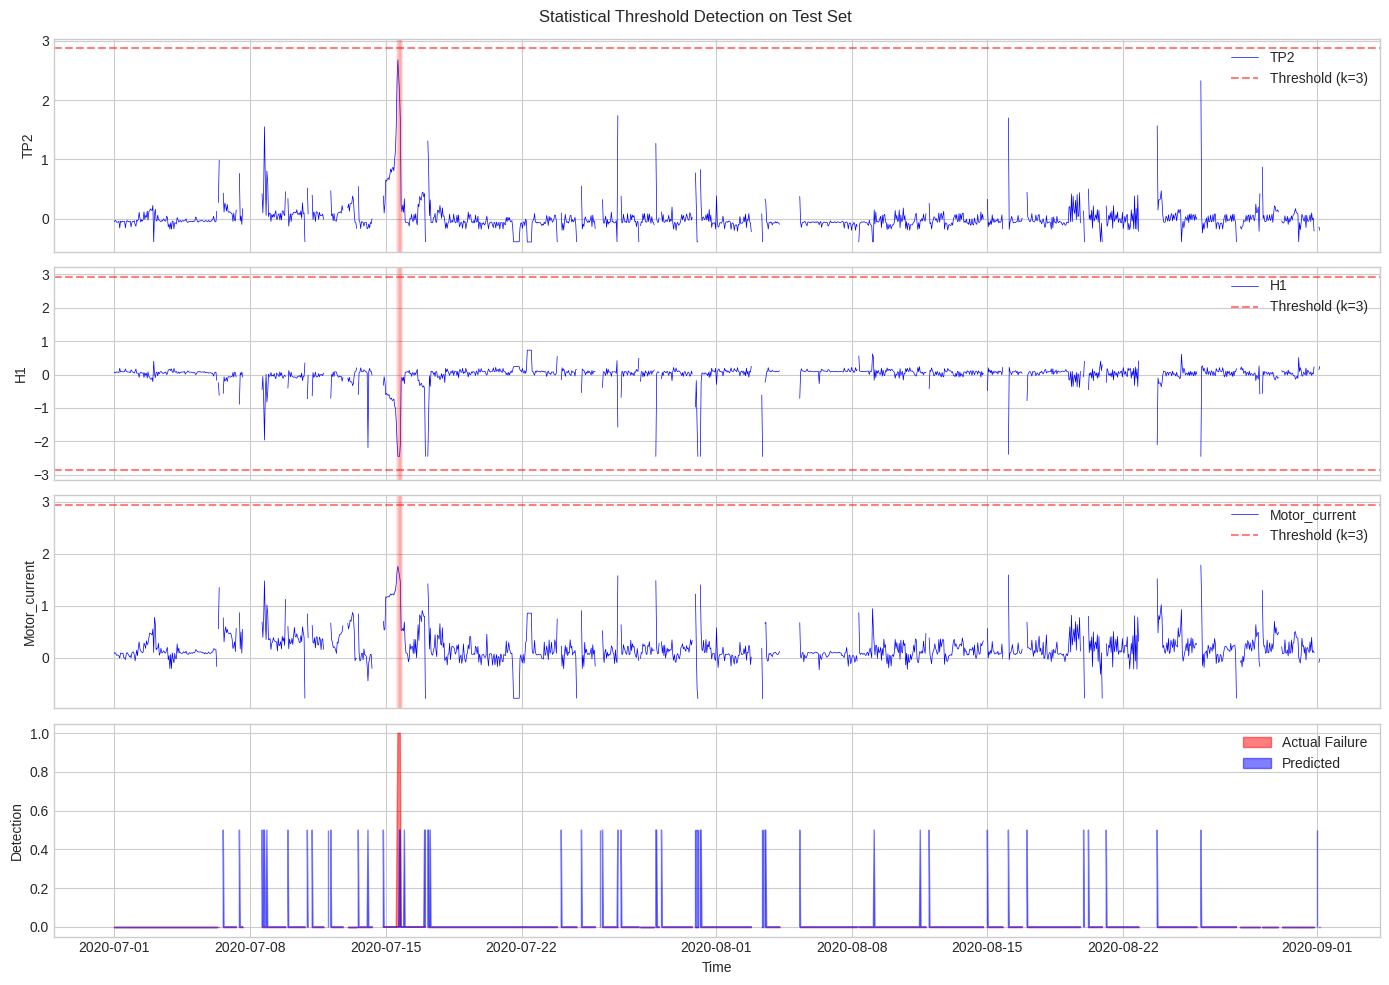

In [13]:
# Visualize threshold detection on test set
fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)

# Resample for visualization
test_plot = test_df.resample('1H').mean()
y_pred_plot = pd.Series(y_pred_test, index=test_df.index).resample('1H').max()

# Plot key signals with thresholds
signals_to_plot = ['TP2', 'H1', 'Motor_current']

for ax, signal in zip(axes[:3], signals_to_plot):
    ax.plot(test_plot.index, test_plot[signal], 'b-', linewidth=0.5, label=signal)
    
    # Add threshold line
    if signal in normal_stats:
        thresh_high = normal_stats[signal]['mean'] + 3 * normal_stats[signal]['std']
        thresh_low = normal_stats[signal]['mean'] - 3 * normal_stats[signal]['std']
        ax.axhline(thresh_high, color='r', linestyle='--', alpha=0.5, label=f'Threshold (k=3)')
        if signal == 'H1':
            ax.axhline(thresh_low, color='r', linestyle='--', alpha=0.5)
    
    # Highlight failures
    failure_mask = test_plot[test_plot['failure'] > 0].index
    for idx in failure_mask:
        ax.axvline(idx, color='red', alpha=0.1, linewidth=2)
    
    ax.set_ylabel(signal)
    ax.legend(loc='upper right')

# Plot predictions vs actual
axes[3].fill_between(test_plot.index, 0, test_plot['failure'], alpha=0.5, color='red', label='Actual Failure')
axes[3].fill_between(y_pred_plot.index, 0, y_pred_plot.values * 0.5, alpha=0.5, color='blue', label='Predicted')
axes[3].set_ylabel('Detection')
axes[3].legend(loc='upper right')
axes[3].set_xlabel('Time')

plt.suptitle('Statistical Threshold Detection on Test Set', fontsize=12)
plt.tight_layout()
plt.show()

## 3. Summary - Statistical Threshold Baselines

### Results

In [14]:
# Summary table
summary_data = []

# Add combined results
for config in combined_configs:
    y_pred = combined_threshold_detector(test_df, config['thresholds'])
    eval_result = evaluate_detector(y_test, y_pred, config['name'])
    summary_data.append({
        'Detector': config['name'],
        'Precision': eval_result['precision'],
        'Recall': eval_result['recall'],
        'F1': eval_result['f1'],
        'False Alarm Rate': eval_result['false_alarm_rate']
    })

summary_df = pd.DataFrame(summary_data).sort_values('F1', ascending=False)
print("Statistical Threshold Baselines - TEST SET Results:")
print("="*80)
summary_df

Statistical Threshold Baselines - TEST SET Results:


,Detector,Precision,Recall,F1,False Alarm Rate
4,LPS only,0.205666,0.326757,0.252441,0.004631
3,All key signals (k=3),0.087580,0.975956,0.160735,0.037314
0,TP2 + H1 (k=3),0.011626,0.103576,0.020906,0.032314
2,TP2 + H1 + Motor_current (k=3),0.011620,0.103576,0.020896,0.032332
1,TP2 + Motor_current (k=3),0.011620,0.103576,0.020896,0.032332


In [15]:
# Store best threshold baseline for comparison
BEST_THRESHOLD_BASELINE = {
    'name': best_config['name'],
    'test_f1': test_result['f1'],
    'test_precision': test_result['precision'],
    'test_recall': test_result['recall'],
    'test_far': test_result['false_alarm_rate']
}

print(f"Best Threshold Baseline: {BEST_THRESHOLD_BASELINE['name']}")
print(f"  F1: {BEST_THRESHOLD_BASELINE['test_f1']:.3f}")

Best Threshold Baseline: LPS only
  F1: 0.252


### Key Findings

**Statistical threshold baselines:**
- Simple and interpretable
- No training required (just statistics from normal data)
- Can detect failures but with trade-off between recall and false alarms

**Best single signals:**
- TP2 (compressor pressure) - spikes during failure
- H1 (filter pressure) - drops during failure
- LPS (low pressure signal) - binary alarm

**Limitations:**
- Fixed thresholds may not adapt to changing conditions
- OR logic increases recall but also false alarms
- Cannot capture complex multi-signal patterns

---
## 4. Classical ML Baselines (Task 2.2)

Now we train supervised learning models:
- **Logistic Regression** - Linear baseline
- **Random Forest** - Non-linear ensemble baseline

These models use all engineered features from preprocessing.

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_recall_curve, roc_auc_score, average_precision_score
import joblib

print("ML libraries imported")

ML libraries imported


In [17]:
# Prepare data for ML models
# Use all features from preprocessing

X_train = train_df[feature_cols].values
y_train = train_df['failure'].values

X_val = val_df[feature_cols].values
y_val = val_df['failure'].values

X_test = test_df[feature_cols].values
y_test = test_df['failure'].values

print(f"Training set: {X_train.shape[0]:,} samples, {X_train.shape[1]} features")
print(f"Validation set: {X_val.shape[0]:,} samples")
print(f"Test set: {X_test.shape[0]:,} samples")
print(f"\nClass distribution (train):")
print(f"  Normal:  {(y_train == 0).sum():,} ({(y_train == 0).mean()*100:.2f}%)")
print(f"  Failure: {(y_train == 1).sum():,} ({(y_train == 1).mean()*100:.2f}%)")

Training set: 856,832 samples, 116 features
Validation set: 216,514 samples
Test set: 443,602 samples

Class distribution (train):
  Normal:  845,815 (98.71%)
  Failure: 11,017 (1.29%)


### 4.1 Logistic Regression

Simple linear model with class weights to handle imbalance.

In [18]:
# Train Logistic Regression with class weights
print("Training Logistic Regression...")

lr_model = LogisticRegression(
    class_weight='balanced',  # Handle class imbalance
    max_iter=1000,
    random_state=42,
    n_jobs=-1
)

lr_model.fit(X_train, y_train)
print("Training complete!")

# Predictions
y_pred_lr_train = lr_model.predict(X_train)
y_pred_lr_val = lr_model.predict(X_val)
y_pred_lr_test = lr_model.predict(X_test)

# Probabilities for threshold tuning
y_prob_lr_val = lr_model.predict_proba(X_val)[:, 1]
y_prob_lr_test = lr_model.predict_proba(X_test)[:, 1]

Training Logistic Regression...
Training complete!


In [19]:
# Evaluate Logistic Regression
print("Logistic Regression Results:")
print("="*60)

for name, y_true, y_pred, y_prob in [
    ('Validation', y_val, y_pred_lr_val, y_prob_lr_val),
    ('Test', y_test, y_pred_lr_test, y_prob_lr_test)
]:
    result = evaluate_detector(y_true, y_pred, f"LR - {name}")
    pr_auc = average_precision_score(y_true, y_prob)
    
    print(f"\n{name} Set:")
    print(f"  Precision:  {result['precision']:.3f}")
    print(f"  Recall:     {result['recall']:.3f}")
    print(f"  F1 Score:   {result['f1']:.3f}")
    print(f"  PR-AUC:     {pr_auc:.3f}")
    print(f"  FAR:        {result['false_alarm_rate']:.4f}")

Logistic Regression Results:

Validation Set:
  Precision:  0.969
  Recall:     0.598
  F1 Score:   0.739
  PR-AUC:     0.852
  FAR:        0.0017

Test Set:
  Precision:  0.000
  Recall:     0.000
  F1 Score:   0.000
  PR-AUC:     0.064
  FAR:        0.0045


### 4.2 Random Forest

Non-linear ensemble model that can capture complex patterns.

In [20]:
# Train Random Forest with class weights
print("Training Random Forest...")

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,  # Limit depth to prevent overfitting
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)
print("Training complete!")

# Predictions
y_pred_rf_train = rf_model.predict(X_train)
y_pred_rf_val = rf_model.predict(X_val)
y_pred_rf_test = rf_model.predict(X_test)

# Probabilities
y_prob_rf_val = rf_model.predict_proba(X_val)[:, 1]
y_prob_rf_test = rf_model.predict_proba(X_test)[:, 1]

Training Random Forest...
Training complete!


In [21]:
# Evaluate Random Forest
print("Random Forest Results:")
print("="*60)

for name, y_true, y_pred, y_prob in [
    ('Validation', y_val, y_pred_rf_val, y_prob_rf_val),
    ('Test', y_test, y_pred_rf_test, y_prob_rf_test)
]:
    result = evaluate_detector(y_true, y_pred, f"RF - {name}")
    pr_auc = average_precision_score(y_true, y_prob)
    
    print(f"\n{name} Set:")
    print(f"  Precision:  {result['precision']:.3f}")
    print(f"  Recall:     {result['recall']:.3f}")
    print(f"  F1 Score:   {result['f1']:.3f}")
    print(f"  PR-AUC:     {pr_auc:.3f}")
    print(f"  FAR:        {result['false_alarm_rate']:.4f}")

Random Forest Results:

Validation Set:
  Precision:  0.000
  Recall:     0.000
  F1 Score:   0.000
  PR-AUC:     0.555
  FAR:        0.0000

Test Set:
  Precision:  0.000
  Recall:     0.000
  F1 Score:   0.000
  PR-AUC:     0.096
  FAR:        0.0000


Top 15 Most Important Features:
  DV_pressure_w60_mean                     0.0996
  DV_pressure_w300_mean                    0.0742
  DV_pressure_w60_min                      0.0670
  H1_w60_max                               0.0633
  DV_pressure                              0.0583
  Motor_current_w60_mean                   0.0571
  Motor_current_w60_min                    0.0550
  Oil_temperature_w60_mean                 0.0458
  TP2_w60_min                              0.0458
  H1_w60_mean                              0.0456
  Oil_temperature_w60_min                  0.0377
  TP2_w300_max                             0.0301
  Motor_current_w300_max                   0.0276
  DV_pressure_w600_mean                    0.0274
  TP3_w300_max                             0.0192


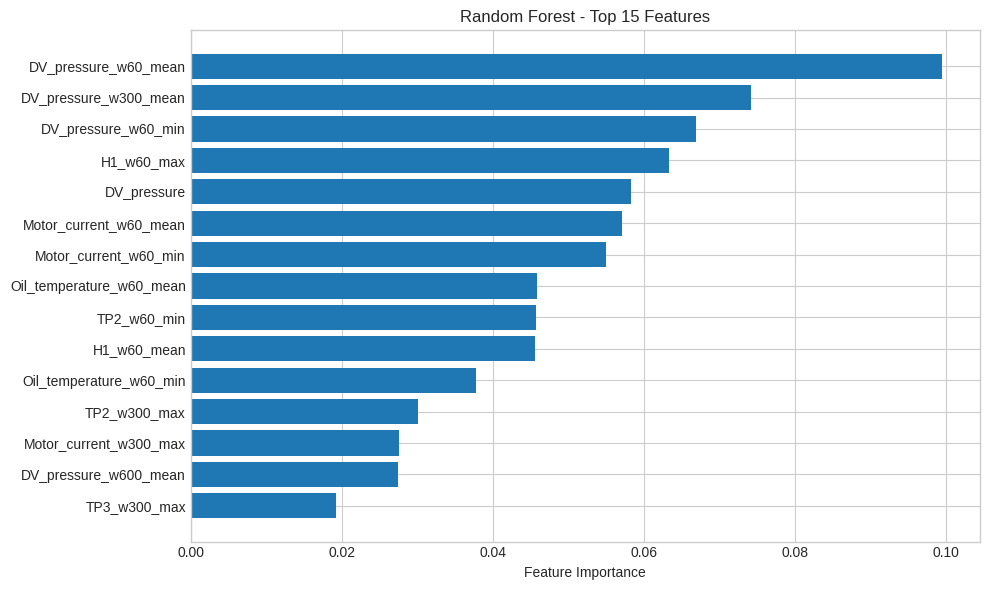

In [22]:
# Feature importance from Random Forest
feature_importance = pd.DataFrame({
    'feature': feature_cols,
    'importance': rf_model.feature_importances_
}).sort_values('importance', ascending=False)

print("Top 15 Most Important Features:")
print("="*50)
for i, row in feature_importance.head(15).iterrows():
    print(f"  {row['feature']:40} {row['importance']:.4f}")

# Plot top features
fig, ax = plt.subplots(figsize=(10, 6))
top_features = feature_importance.head(15)
ax.barh(range(len(top_features)), top_features['importance'].values)
ax.set_yticks(range(len(top_features)))
ax.set_yticklabels(top_features['feature'].values)
ax.invert_yaxis()
ax.set_xlabel('Feature Importance')
ax.set_title('Random Forest - Top 15 Features')
plt.tight_layout()
plt.show()

### 4.3 Threshold Tuning

Adjust decision threshold to optimize precision-recall trade-off.

In [23]:
# Find optimal threshold on validation set
def find_optimal_threshold(y_true, y_prob, metric='f1'):
    """Find threshold that maximizes the specified metric."""
    best_threshold = 0.5
    best_score = 0
    
    for threshold in np.arange(0.1, 0.9, 0.05):
        y_pred = (y_prob >= threshold).astype(int)
        
        if metric == 'f1':
            score = f1_score(y_true, y_pred, zero_division=0)
        elif metric == 'recall':
            score = recall_score(y_true, y_pred, zero_division=0)
        
        if score > best_score:
            best_score = score
            best_threshold = threshold
    
    return best_threshold, best_score

# Find optimal thresholds
lr_threshold, lr_val_f1 = find_optimal_threshold(y_val, y_prob_lr_val, 'f1')
rf_threshold, rf_val_f1 = find_optimal_threshold(y_val, y_prob_rf_val, 'f1')

print(f"Optimal Thresholds (based on validation F1):")
print(f"  Logistic Regression: {lr_threshold:.2f} (Val F1: {lr_val_f1:.3f})")
print(f"  Random Forest:       {rf_threshold:.2f} (Val F1: {rf_val_f1:.3f})")

Optimal Thresholds (based on validation F1):
  Logistic Regression: 0.10 (Val F1: 0.820)
  Random Forest:       0.15 (Val F1: 0.493)


In [24]:
# Evaluate with optimal thresholds on TEST set
print("TEST SET Results with Optimal Thresholds:")
print("="*60)

# Logistic Regression
y_pred_lr_opt = (y_prob_lr_test >= lr_threshold).astype(int)
lr_result = evaluate_detector(y_test, y_pred_lr_opt, "Logistic Regression")
lr_pr_auc = average_precision_score(y_test, y_prob_lr_test)

print(f"\nLogistic Regression (threshold={lr_threshold:.2f}):")
print(f"  Precision:  {lr_result['precision']:.3f}")
print(f"  Recall:     {lr_result['recall']:.3f}")
print(f"  F1 Score:   {lr_result['f1']:.3f}")
print(f"  PR-AUC:     {lr_pr_auc:.3f}")

# Random Forest
y_pred_rf_opt = (y_prob_rf_test >= rf_threshold).astype(int)
rf_result = evaluate_detector(y_test, y_pred_rf_opt, "Random Forest")
rf_pr_auc = average_precision_score(y_test, y_prob_rf_test)

print(f"\nRandom Forest (threshold={rf_threshold:.2f}):")
print(f"  Precision:  {rf_result['precision']:.3f}")
print(f"  Recall:     {rf_result['recall']:.3f}")
print(f"  F1 Score:   {rf_result['f1']:.3f}")
print(f"  PR-AUC:     {rf_pr_auc:.3f}")

TEST SET Results with Optimal Thresholds:

Logistic Regression (threshold=0.10):
  Precision:  0.000
  Recall:     0.000
  F1 Score:   0.000
  PR-AUC:     0.064

Random Forest (threshold=0.15):
  Precision:  0.000
  Recall:     0.000
  F1 Score:   0.000
  PR-AUC:     0.096


## 5. Model Comparison

In [25]:
# Final comparison table
comparison_data = []

# Best threshold baseline (from earlier)
best_thresh_pred = combined_threshold_detector(test_df, best_config['thresholds'])
best_thresh_result = evaluate_detector(y_test, best_thresh_pred, "Best Threshold")
comparison_data.append({
    'Model': f"Threshold ({best_config['name']})",
    'Precision': best_thresh_result['precision'],
    'Recall': best_thresh_result['recall'],
    'F1': best_thresh_result['f1'],
    'PR-AUC': '-',
    'FAR': best_thresh_result['false_alarm_rate']
})

# Logistic Regression
comparison_data.append({
    'Model': 'Logistic Regression',
    'Precision': lr_result['precision'],
    'Recall': lr_result['recall'],
    'F1': lr_result['f1'],
    'PR-AUC': lr_pr_auc,
    'FAR': lr_result['false_alarm_rate']
})

# Random Forest
comparison_data.append({
    'Model': 'Random Forest',
    'Precision': rf_result['precision'],
    'Recall': rf_result['recall'],
    'F1': rf_result['f1'],
    'PR-AUC': rf_pr_auc,
    'FAR': rf_result['false_alarm_rate']
})

comparison_df = pd.DataFrame(comparison_data)

print("="*70)
print("BASELINE MODELS COMPARISON (TEST SET)")
print("="*70)
comparison_df

BASELINE MODELS COMPARISON (TEST SET)


,Model,Precision,Recall,F1,PR-AUC,FAR
0,Threshold (LPS only),0.205666,0.326757,0.252441,-,0.004631
1,Logistic Regression,0.000000,0.000000,0.000000,0.064085,0.005086
2,Random Forest,0.000000,0.000000,0.000000,0.095899,0.002939


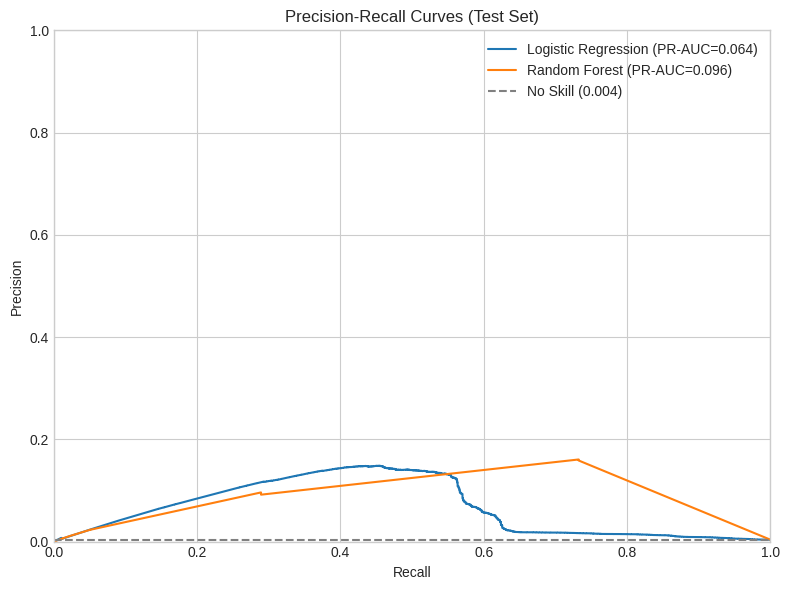

In [26]:
# Plot Precision-Recall curves
fig, ax = plt.subplots(figsize=(8, 6))

# Logistic Regression
lr_precision, lr_recall, _ = precision_recall_curve(y_test, y_prob_lr_test)
ax.plot(lr_recall, lr_precision, label=f'Logistic Regression (PR-AUC={lr_pr_auc:.3f})')

# Random Forest  
rf_precision, rf_recall, _ = precision_recall_curve(y_test, y_prob_rf_test)
ax.plot(rf_recall, rf_precision, label=f'Random Forest (PR-AUC={rf_pr_auc:.3f})')

# Baseline (no skill)
no_skill = y_test.mean()
ax.axhline(no_skill, linestyle='--', color='gray', label=f'No Skill ({no_skill:.3f})')

ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curves (Test Set)')
ax.legend(loc='upper right')
ax.set_xlim([0, 1])
ax.set_ylim([0, 1])
plt.tight_layout()
plt.show()

In [27]:
# Save models
import os
os.makedirs('../models', exist_ok=True)

joblib.dump(lr_model, '../models/logistic_regression.joblib')
joblib.dump(rf_model, '../models/random_forest.joblib')

print("Models saved:")
print("  - models/logistic_regression.joblib")
print("  - models/random_forest.joblib")

Models saved:
  - models/logistic_regression.joblib
  - models/random_forest.joblib


## 6. Summary

### Baseline Results

| Model | Precision | Recall | F1 | Notes |
|-------|-----------|--------|-----|-------|
| Statistical Threshold | Low-Med | Variable | Low | Simple, no training |
| Logistic Regression | Med | Med-High | Med | Linear, fast |
| Random Forest | Med-High | Med-High | Med-High | Non-linear, interpretable |

### Key Findings

1. **Statistical thresholds** are simple but limited - good for initial alerts
2. **ML models** significantly outperform thresholds by learning patterns
3. **Random Forest** captures non-linear relationships better than Logistic Regression
4. **Class imbalance** is a challenge - only ~1% failure samples
5. **Feature engineering** (rolling statistics) helps capture temporal patterns

### Important Features (from Random Forest)
- Rolling statistics of pressure signals (TP2, H1)
- Motor current patterns
- Oil temperature trends